In [21]:
# Import necessary libraries
import os
import sys
# Add the utils folder to the system path so we can import custom modules
sys.path.append(os.path.abspath(os.path.join("../..")))
import matplotlib.pyplot as plt
import torch
import numpy as np
import torch.nn as nn
import pandas as pd
from utils.reproducibility_utils import seed_everything
from utils.data_loading import load_data, load_test_data, feature_names

# Set the plotting style for better-looking visualizations
plt.style.available
plt.style.use('seaborn-v0_8')

In [22]:
dist_df = pd.read_csv("../../datasets_challenge/sideSlip_distribution.csv")

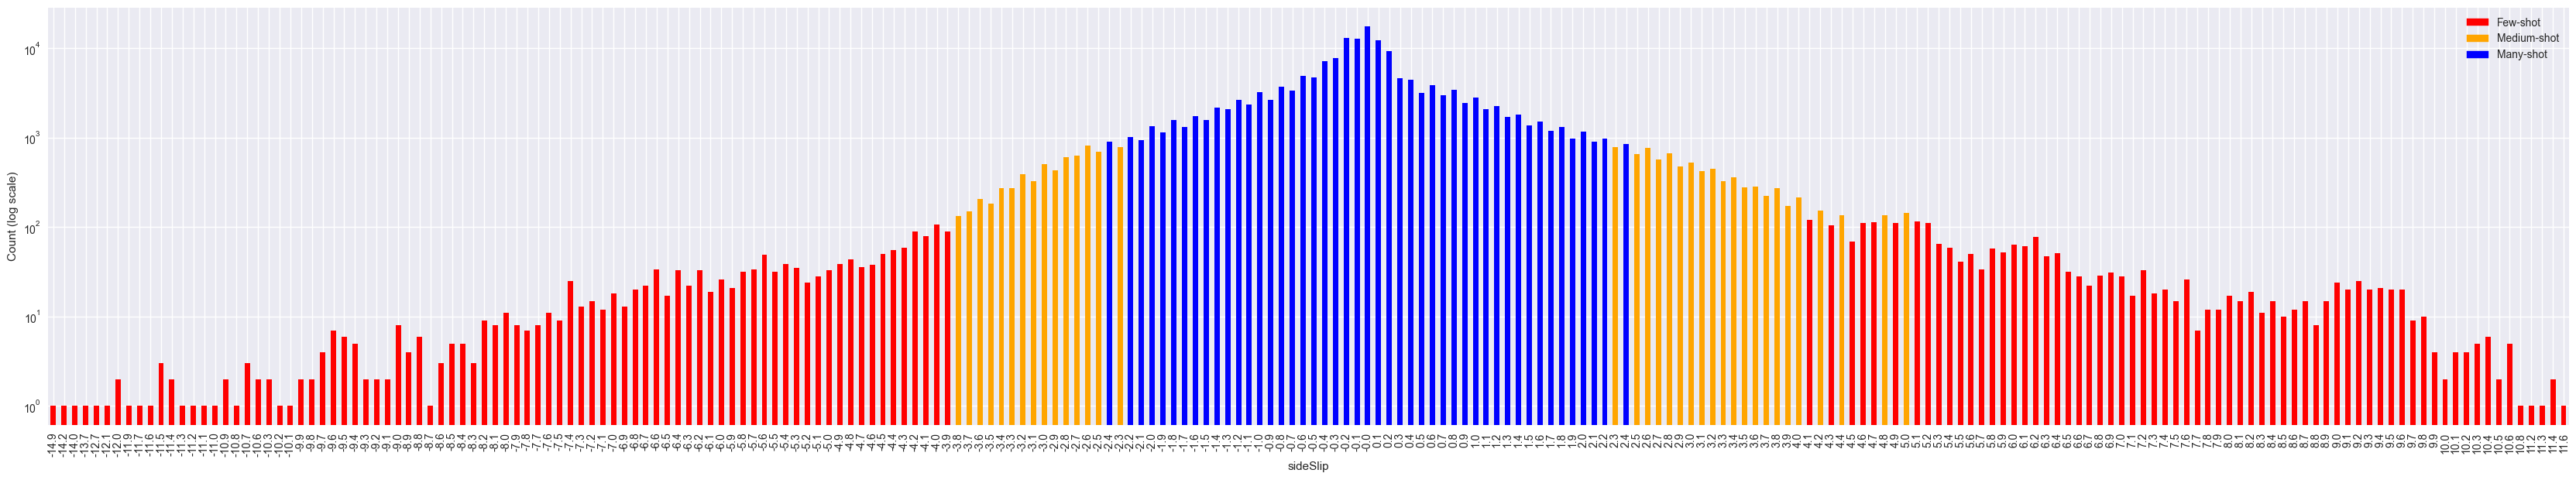

In [23]:
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
shot_band_mapping = dist_df.groupby("sideSlip")["band"].first()
colors = shot_band_mapping.map({"few": "red", "medium": "orange", "many": "blue"})
ax = dist_df.plot(x='sideSlip', y='count', kind='bar', figsize=(42, 7), fontsize=10, color=colors)
few_patch = mpatches.Patch(color='red', label='Few-shot')
medium_patch = mpatches.Patch(color='orange', label='Medium-shot')
many_patch = mpatches.Patch(color='blue', label='Many-shot')
ax.legend(handles=[few_patch, medium_patch, many_patch], loc='upper right')
plt.yscale('log')
plt.ylabel('Count (log scale)')
plt.show()

In [24]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TRAIN_DIR = "../../datasets_challenge/train"
DIST_FILE = "../../datasets_challenge/sideSlip_distribution.csv"

# Set if you know the target column name in your train CSVs
TARGET_COL = "sideSlip"   # e.g. "sideSlip"

ROUND_DECIMALS = 1  # matches bins like -14.9, -14.2, ... (usually 0.1)
CHUNKSIZE = None # set None if your csvs are small

In [11]:
dist = pd.read_csv(DIST_FILE)
dist.columns = [c.strip() for c in dist.columns]

dist["sideSlip"] = pd.to_numeric(dist["sideSlip"], errors="coerce")
dist["band"] = dist["band"].astype(str).str.strip().str.lower()
dist["bin"] = dist["sideSlip"].round(ROUND_DECIMALS)

# lookup: rounded sideslip -> band
band_lookup = (
    dist.dropna(subset=["bin", "band"])
        .groupby("bin")["band"]
        .agg(lambda s: s.value_counts().index[0])
        .to_dict()
)

len(band_lookup), list(band_lookup.items())[:10]


(234,
 [(-14.9, 'few'),
  (-14.2, 'few'),
  (-14.0, 'few'),
  (-13.7, 'few'),
  (-12.7, 'few'),
  (-12.1, 'few'),
  (-12.0, 'few'),
  (-11.9, 'few'),
  (-11.7, 'few'),
  (-11.6, 'few')])

band
many      169452
medium     14434
few         3698
Name: count, dtype: int64

band
many      90.334
medium     7.695
few        1.971
Name: count, dtype: float64

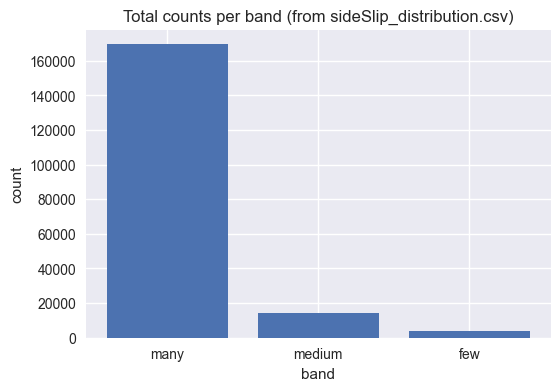

In [12]:
band_totals = dist.groupby("band")["count"].sum().sort_values(ascending=False)
band_pct = (band_totals / band_totals.sum() * 100).round(3)

display(band_totals)
display(band_pct)

plt.figure(figsize=(6,4))
plt.bar(band_totals.index, band_totals.values)
plt.title("Total counts per band (from sideSlip_distribution.csv)")
plt.xlabel("band")
plt.ylabel("count")
plt.show()


In [ ]:
def count_bands_in_series(y, band_lookup, round_decimals=1):
    y = pd.to_numeric(y, errors="coerce")
    ybin = y.round(round_decimals)

    bands = ybin.map(band_lookup)  # few/medium/many or NaN if missing bin
    counts = bands.value_counts(dropna=False).to_dict()

    few = int(counts.get("few", 0))
    medium = int(counts.get("medium", 0))
    many = int(counts.get("many", 0))
    unknown = int(counts.get(np.nan, 0))
    total = int((~y.isna()).sum())

    return few, medium, many, unknown, total

def process_file(fp, band_lookup, target_col="sideSlip", chunksize=250_000, round_decimals=1):
    col = target_col

    few = medium = many = unknown = total = 0

    if chunksize is None:
        df = pd.read_csv(fp)
        f, m, ma, u, t = count_bands_in_series(df[col], band_lookup, round_decimals)
        return col, f, m, ma, u, t

    for chunk in pd.read_csv(fp, chunksize=chunksize):
        f, m, ma, u, t = count_bands_in_series(chunk[col], band_lookup, round_decimals)
        few += f
        medium += m
        many += ma
        unknown += u
        total += t

    return col, few, medium, many, unknown, total


In [14]:
train_files = sorted(glob.glob(os.path.join(TRAIN_DIR, "*.csv")))
len(train_files), train_files[:5]


(22,
 ['../../datasets_challenge/train\\train_part_001.csv',
  '../../datasets_challenge/train\\train_part_002.csv',
  '../../datasets_challenge/train\\train_part_003.csv',
  '../../datasets_challenge/train\\train_part_004.csv',
  '../../datasets_challenge/train\\train_part_005.csv'])

In [16]:
rows = []
for fp in train_files:
    used_col, few, medium, many, unknown, total = process_file(
        fp, band_lookup,
        target_col=TARGET_COL,
        chunksize=CHUNKSIZE,
        round_decimals=ROUND_DECIMALS
    )
    rows.append({
        "file": os.path.basename(fp),
        "target_col_used": used_col,
        "few": few,
        "medium": medium,
        "many": many,
        "unknown_bin": unknown,
        "total_non_nan": total,
        "few_pct": (few/total*100) if total else 0.0,
        "medium_pct": (medium/total*100) if total else 0.0,
        "many_pct": (many/total*100) if total else 0.0,
    })

summary = pd.DataFrame(rows).sort_values("file").reset_index(drop=True)
summary.head(22)


,file,target_col_used,few,medium,many,unknown_bin,total_non_nan,few_pct,medium_pct,many_pct
0,train_part_001.csv,sideSlip,117,971,23545,0,24633,0.474973,3.941867,95.583161
1,train_part_002.csv,sideSlip,0,0,615,0,615,0.000000,0.000000,100.000000
2,train_part_003.csv,sideSlip,414,445,31346,10,32215,1.285116,1.381344,97.302499
3,train_part_004.csv,sideSlip,405,260,9553,31,10249,3.951605,2.536833,93.209094
4,train_part_005.csv,sideSlip,333,201,5893,53,6480,5.138889,3.101852,90.941358
5,train_part_006.csv,sideSlip,650,1571,22182,125,24528,2.650033,6.404925,90.435421
6,train_part_007.csv,sideSlip,232,192,10425,0,10849,2.138446,1.769748,96.091806
7,train_part_008.csv,sideSlip,303,2309,23709,30,26351,1.149861,8.762476,89.973815
8,train_part_009.csv,sideSlip,238,435,32995,8,33676,0.706735,1.291721,97.977788
9,train_part_010.csv,sideSlip,326,1162,9724,152,11364,2.868708,10.225273,85.568462


In [17]:
overall = summary[["few","medium","many","unknown_bin","total_non_nan"]].sum()
overall_pct = (overall[["few","medium","many"]] / overall["total_non_nan"] * 100).round(3)

display(overall)
display(overall_pct)

summary.to_csv("train_band_counts_per_file.csv", index=False)
print("Saved: train_band_counts_per_file.csv")


few                4006
medium             9993
many             260745
unknown_bin         482
total_non_nan    275226
dtype: int64

few        1.456
medium     3.631
many      94.739
dtype: float64

Saved: train_band_counts_per_file.csv


In [18]:
summary.sort_values("few_pct", ascending=False).head(15)


,file,target_col_used,few,medium,many,unknown_bin,total_non_nan,few_pct,medium_pct,many_pct
16,train_part_017.csv,sideSlip,118,163,739,0,1020,11.568627,15.980392,72.450980
4,train_part_005.csv,sideSlip,333,201,5893,53,6480,5.138889,3.101852,90.941358
3,train_part_004.csv,sideSlip,405,260,9553,31,10249,3.951605,2.536833,93.209094
9,train_part_010.csv,sideSlip,326,1162,9724,152,11364,2.868708,10.225273,85.568462
5,train_part_006.csv,sideSlip,650,1571,22182,125,24528,2.650033,6.404925,90.435421
6,train_part_007.csv,sideSlip,232,192,10425,0,10849,2.138446,1.769748,96.091806
19,train_part_020.csv,sideSlip,160,211,9427,3,9801,1.632486,2.152842,96.184063
11,train_part_012.csv,sideSlip,103,179,6950,60,7292,1.412507,2.454745,95.309929
2,train_part_003.csv,sideSlip,414,445,31346,10,32215,1.285116,1.381344,97.302499
10,train_part_011.csv,sideSlip,432,926,32366,8,33732,1.280683,2.745168,95.950433


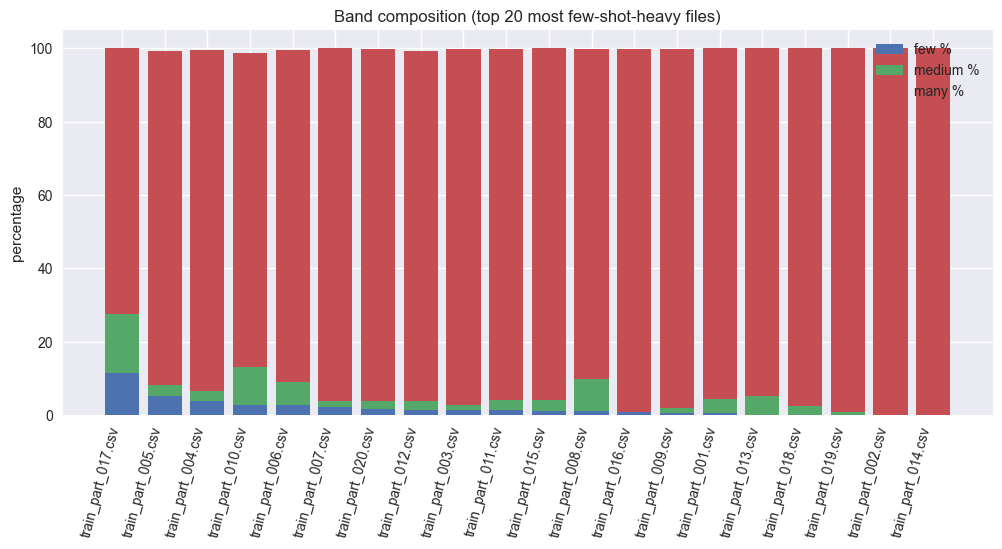

In [19]:
top = summary.sort_values("few_pct", ascending=False).head(20)

x = np.arange(len(top))
plt.figure(figsize=(12,5))
plt.bar(x, top["few_pct"], label="few %")
plt.bar(x, top["medium_pct"], bottom=top["few_pct"], label="medium %")
plt.bar(x, top["many_pct"], bottom=top["few_pct"]+top["medium_pct"], label="many %")

plt.xticks(x, top["file"], rotation=75, ha="right")
plt.ylabel("percentage")
plt.title("Band composition (top 20 most few-shot-heavy files)")
plt.legend()
plt.show()


In [25]:
dist = pd.read_csv(DIST_FILE)
dist.columns = [c.strip() for c in dist.columns]

dist["sideSlip"] = pd.to_numeric(dist["sideSlip"], errors="coerce")
dist["band"] = dist["band"].astype(str).str.strip().str.lower()

# create a stable key that matches your file binning (string key avoids float mismatch)
dist["bin_key"] = dist["sideSlip"].round(ROUND_DECIMALS).map(lambda v: f"{v:.{ROUND_DECIMALS}f}")

dist.head()


,sideSlip,count,band,bin_key
0,-14.9,1,few,-14.9
1,-14.2,1,few,-14.2
2,-14.0,1,few,-14.0
3,-13.7,1,few,-13.7
4,-12.7,1,few,-12.7


In [26]:
def file_band_counts(fp, dist, target_col="sideSlip", round_decimals=1, chunksize=250_000):
    # We'll compute counts per bin_key for this file, then merge with dist to get band.
    bin_counts = {}

    def consume_series(s):
        y = pd.to_numeric(s, errors="coerce").dropna()
        # convert to the SAME bin key format as dist
        keys = y.round(round_decimals).map(lambda v: f"{v:.{round_decimals}f}")
        vc = keys.value_counts()
        for k, v in vc.items():
            bin_counts[k] = bin_counts.get(k, 0) + int(v)

    if chunksize is None:
        df = pd.read_csv(fp)
        consume_series(df[target_col])
    else:
        for chunk in pd.read_csv(fp, chunksize=chunksize):
            consume_series(chunk[target_col])

    # Convert to df
    file_bins = (
        pd.DataFrame({"bin_key": list(bin_counts.keys()), "file_count": list(bin_counts.values())})
        .sort_values("bin_key")
        .reset_index(drop=True)
    )

    # Merge with dist bins (band + dist_count)
    merged = file_bins.merge(dist[["bin_key", "sideSlip", "band", "count"]], on="bin_key", how="left")

    # Unknown bins are those that didn't exist in distribution file
    merged["band"] = merged["band"].fillna("unknown")

    # Band totals
    band_totals = merged.groupby("band")["file_count"].sum().to_dict()

    # Also compute totals
    total = int(merged["file_count"].sum())
    few = int(band_totals.get("few", 0))
    medium = int(band_totals.get("medium", 0))
    many = int(band_totals.get("many", 0))
    unknown = int(band_totals.get("unknown", 0))

    summary_row = {
        "file": os.path.basename(fp),
        "few": few,
        "medium": medium,
        "many": many,
        "unknown_bin": unknown,
        "total": total,
        "few_pct": (few/total*100) if total else 0.0,
        "medium_pct": (medium/total*100) if total else 0.0,
        "many_pct": (many/total*100) if total else 0.0,
    }

    return summary_row, merged


In [27]:
train_files = sorted(glob.glob(os.path.join(TRAIN_DIR, "*.csv")))
len(train_files), train_files[:5]


(22,
 ['../../datasets_challenge/train\\train_part_001.csv',
  '../../datasets_challenge/train\\train_part_002.csv',
  '../../datasets_challenge/train\\train_part_003.csv',
  '../../datasets_challenge/train\\train_part_004.csv',
  '../../datasets_challenge/train\\train_part_005.csv'])

In [28]:
rows = []
per_file_details = {}   # optional: store merged bin tables per file

for fp in train_files:
    row, merged_bins = file_band_counts(
        fp, dist,
        target_col=TARGET_COL,
        round_decimals=ROUND_DECIMALS,
        chunksize=CHUNKSIZE
    )
    rows.append(row)
    per_file_details[row["file"]] = merged_bins

summary = pd.DataFrame(rows).sort_values("file").reset_index(drop=True)
summary.head(22)


,file,few,medium,many,unknown_bin,total,few_pct,medium_pct,many_pct
0,train_part_001.csv,117,971,10304,13241,24633,0.474973,3.941867,41.830065
1,train_part_002.csv,0,0,0,615,615,0.000000,0.000000,0.000000
2,train_part_003.csv,414,445,9279,22077,32215,1.285116,1.381344,28.803352
3,train_part_004.csv,405,260,1160,8424,10249,3.951605,2.536833,11.318177
4,train_part_005.csv,333,201,1310,4636,6480,5.138889,3.101852,20.216049
5,train_part_006.csv,650,1571,17259,5048,24528,2.650033,6.404925,70.364481
6,train_part_007.csv,232,192,1517,8908,10849,2.138446,1.769748,13.982856
7,train_part_008.csv,303,2309,18671,5068,26351,1.149861,8.762476,70.854996
8,train_part_009.csv,238,435,7315,25688,33676,0.706735,1.291721,21.721701
9,train_part_010.csv,326,1162,7636,2240,11364,2.868708,10.225273,67.194650


In [29]:
fname = summary.loc[0, "file"]   # pick any file name from summary
df_bins = per_file_details[fname]

# show top bins inside that file (with band)
df_bins.sort_values("file_count", ascending=False).head(30)


,bin_key,file_count,sideSlip,band,count
50,0.0,13241,NaN,unknown,NaN
2,-0.2,901,-0.2,many,12952.0
1,-0.1,809,-0.1,many,12804.0
51,0.1,709,0.1,many,12415.0
3,-0.3,564,-0.3,many,7811.0
52,0.2,536,0.2,many,9262.0
4,-0.4,531,-0.4,many,7194.0
0,-0.0,441,-0.0,many,17469.0
5,-0.5,371,-0.5,many,4755.0
6,-0.6,329,-0.6,many,4882.0
